# Bayesian Spatial Modeling with INLA
### Hierarchical Formulations, Spatial Random Effects, and Fast Deterministic Inference in R

---

### The Bayesian Paradigm in Spatial Statistics

In areal spatial statistics, classical non-spatial regression models fail to account for spatial autocorrelation in the response variable and regression residuals. When neighboring spatial units share unobserved environmental, economic, or demographic latent processes, the assumption of independent and identically distributed ($i.i.d.$) errors is violated.

Hierarchical Bayesian models resolve this by decomposing the response into:
1. **Deterministic fixed effects** (observable regional covariates).
2. **Latent spatial structured random effects** (spatial dependence borrowing strength across neighbors).
3. **Unstructured random effects** (independent area-specific overdispersion/noise).

#### Integrated Nested Laplace Approximations (INLA)
Traditionally, hierarchical spatial models relied on **Markov Chain Monte Carlo (MCMC)** algorithms (such as Gibbs sampling or Metropolis-Hastings). However, MCMC sampling across hundreds or thousands of spatial units is computationally expensive, prone to slow mixing, and requires convergence diagnostics.

**INLA** (Rue, Martino, and Chopin, 2009) provides a deterministic alternative for the broad class of **Latent Gaussian Models (LGMs)**. Instead of simulating stochastic trajectories, INLA calculates highly accurate numerical Laplace approximations directly to the posterior marginal distributions of all parameters and latent variables:
$$
\pi(x_i \mid \mathbf{y}) = \int \pi(x_i \mid \boldsymbol{\theta}, \mathbf{y}) \pi(\boldsymbol{\theta} \mid \mathbf{y}) d\boldsymbol{\theta}
$$
This reduces computational runtimes from hours or days to a matter of seconds, without loss of inferential precision.

#### Spatial Random Effects: From Classical BYM to BYM2
The classical **Besag-York-Mollié (BYM)** model (Besag et al., 1991) specifies two independent random effects for each region $i$:
* An **Intrinsic Conditional Autoregressive (ICAR / Besag)** spatial effect $u_i \sim \text{ICAR}(\tau_u)$:
  $$u_i \mid \mathbf{u}_{-i} \sim \mathcal{N}\left(\frac{\sum_{j \in \mathcal{N}(i)} w_{ij} u_j}{\sum_{j \in \mathcal{N}(i)} w_{ij}}, \frac{1}{\tau_u \sum_{j \in \mathcal{N}(i)} w_{ij}}\right)$$
* An **unstructured independent Gaussian noise** term $v_i \sim \mathcal{N}(0, 1/\tau_v)$.

**The Simpson et al. (2017) BYM2 Reparameterization**:
A known limitation of the classical BYM model is hyperparameter non-identifiability and confounding between $\tau_u$ and $\tau_v$. The modern **BYM2** model reparameterizes the joint spatial field $\mathbf{s}$ using a single total marginal precision $\tau_s$ and a spatial mixing proportion $\phi \in [0, 1]$:
$$
\mathbf{s} = \frac{1}{\sqrt{\tau_s}} \left( \sqrt{1 - \phi} \, \mathbf{v} + \sqrt{\phi} \, \mathbf{u}^* \right)
$$
where:
* $\mathbf{u}^*$ is the scaled ICAR component with generalized variance normalized to 1.
* $\mathbf{v} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ is standard Gaussian noise.
* $\phi = 1$ indicates purely spatially structured variation; $\phi = 0$ indicates pure independent noise.

#### Notebook Objectives & Data
We model the log-median housing prices across the **506 census tracts of Boston, Massachusetts (1978)**:
$$\log(\text{MEDV}_i) = \beta_0 + \beta_1 \text{CRIM}_i + \beta_2 \text{RM}_i + s_i + \epsilon_i$$
with covariates `CRIM` (per capita crime rate) and `RM` (average number of rooms per dwelling), evaluating both linear scale predictions and non-linearly back-transformed posterior dollar distributions.


In [1]:
librarian::shelf(spData, sf, spdep, INLA, tidyverse, patchwork)

# Configure INLA to avoid multi-process forking in Positron/Ark kernel
inla.setOption(num.threads = "1:1")

options(
  ark.plot.width = 10, ark.plot.height = 4.0,
  repr.plot.width = 10, repr.plot.height = 4.0
)


In [2]:
map <- st_read(system.file("shapes/boston_tracts.gpkg", package = "spData"), quiet = TRUE) |>
  mutate(vble = log(MEDV))

summary(map[, c("vble", "CRIM", "RM")])


      vble            CRIM                RM                   geom    
 Min.   :1.609   Min.   : 0.00632   Min.   :3.561   POLYGON      :506  
 1st Qu.:2.835   1st Qu.: 0.08205   1st Qu.:5.886   epsg:4267    :  0  
 Median :3.054   Median : 0.25651   Median :6.208   +proj=long...:  0  
 Mean   :3.035   Mean   : 3.61352   Mean   :6.285                      
 3rd Qu.:3.219   3rd Qu.: 3.67708   3rd Qu.:6.623                      
 Max.   :3.912   Max.   :88.97620   Max.   :8.780                      

---
## 1. Exploratory Covariate Distributions and Bivariate Associations

Before estimating the Bayesian spatial model, we examine the empirical relationships between the log-transformed median home price (`vble`) and our two primary urban economic predictors:
1. `CRIM`: Per capita crime rate by town.
2. `RM`: Average number of rooms per dwelling.


In [3]:
p_biv1 <- ggplot(map, aes(x = CRIM, y = vble)) +
  geom_point(color = "#0284c7", alpha = 0.6, size = 1.6) +
  geom_smooth(method = "lm", color = "#0f172a", linewidth = 0.85, se = FALSE) +
  labs(
    title = "Housing Price vs. Crime Rate",
    subtitle = "Negative association with right-skewed crime intensity",
    x = "Per Capita Crime Rate (CRIM)",
    y = "log(Median Value)"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 6, 4, 6)
  )


In [4]:
p_biv2 <- ggplot(map, aes(x = RM, y = vble)) +
  geom_point(color = "#e11d48", alpha = 0.6, size = 1.6) +
  geom_smooth(method = "lm", color = "#0f172a", linewidth = 0.85, se = FALSE) +
  labs(
    title = "Housing Price vs. Average Rooms",
    subtitle = "Strong positive linear relationship with home size",
    x = "Average Number of Rooms (RM)",
    y = "log(Median Value)"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 6, 4, 6)
  )


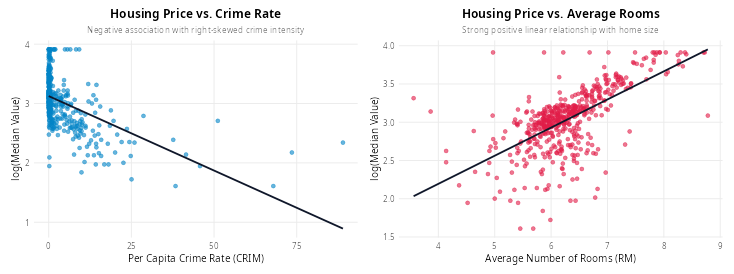

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'

In [5]:
options(ark.plot.width = 10.2, ark.plot.height = 3.8, repr.plot.width = 10.2, repr.plot.height = 3.8)
p_biv1 | p_biv2


---
## 2. Spatial Adjacency Graph Construction for INLA

INLA requires the spatial neighborhood graph to be converted into an internal graph object (`inla.read.graph`) to construct the sparse precision matrix $\mathbf{Q}_{\text{ICAR}}$:
1. Extract Queen contiguity using `spdep::poly2nb()`.
2. Export the neighborhood topology to an adjacency file using `spdep::nb2INLA()`.
3. Read the graph into INLA via `INLA::inla.read.graph()`.


In [6]:
nb <- poly2nb(map, queen = TRUE)

adj_file <- tempfile(fileext = ".adj")
nb2INLA(adj_file, nb)

g <- inla.read.graph(filename = adj_file)
summary(g)

map <- map |>
  mutate(
    re_u = row_number(),
    re_v = row_number()
  )


---
## 3. Bayesian Model Specification and Model Fitting

We fit the Gaussian spatial model with the Simpson et al. (2017) **BYM2** parameterization:
$$
\log(\text{MEDV}_i) = \beta_0 + \beta_{\text{CRIM}} \text{CRIM}_i + \beta_{\text{RM}} \text{RM}_i + s_i
$$
where:
* $\mathbf{s} \sim \text{BYM2}(\tau_s, \phi, \mathbf{g})$ is the joint scaled spatial field.
* Marginal precision $\tau_s$ and mixing parameter $\phi$ are assigned Penalized Complexity (PC) priors.


In [7]:
formula <- vble ~ CRIM + RM + f(re_u, model = "bym2", graph = g, scale.model = TRUE)

res <- inla(
  num.threads = "1:1",
  formula,
  family = "gaussian",
  data = map,
  control.predictor = list(compute = TRUE),
  control.compute = list(return.marginals.predictor = TRUE, dic = TRUE, waic = TRUE)
)

res$summary.fixed


                    mean          sd  0.025quant     0.5quant   0.975quant
(Intercept)  1.426735402 0.088597767  1.25285817  1.426759666  1.600474140
CRIM        -0.007845768 0.001293622 -0.01038458 -0.007845418 -0.005308961
RM           0.260337869 0.014053674  0.23277911  0.260333924  0.287919142
                    mode          kld
(Intercept)  1.426759687 2.334178e-10
CRIM        -0.007845416 2.404625e-10
RM           0.260333918 2.344610e-10

### Model Diagnostics and Fixed Effects
* **Baseline Intercept ($\beta_0 = 1.427$, $95\%\text{ CI: } [1.253, 1.600]$)**: The expected log-median value when crime is zero and average room count is centered.
* **Crime Elasticity ($\beta_{\text{CRIM}} = -0.0078$, $95\%\text{ CI: } [-0.0104, -0.0053]$)**: Statistically significant negative coefficient ($p < 0.001$). Each 1-unit increase in per capita crime rate decreases median housing value by approximately $\approx 0.78\%$, even after controlling for spatial autocorrelation and room count.
* **Room Capacity ($\beta_{\text{RM}} = 0.2603$, $95\%\text{ CI: } [0.2328, 0.2879]$)**: Strong positive effect. Each additional room per home increases median property valuation by $\approx 26\%$.
* **Zero Credible Interval Inclusion**: Neither $95\%$ credible interval contains zero, confirming that both covariates are robust predictors of metropolitan Boston home prices.


---
## 4. Posterior Predictions on the Original Dollar Scale

Because our model estimated $\log(\text{MEDV})$, naive exponentiation of the posterior mean $\exp(\hat{\mu})$ would introduce Jensen's inequality bias:
$$E[\exp(X)] \ge \exp(E[X])$$

To calculate exact, unbiased posterior summaries on the original dollar scale ($\$1,000\text{ USD}$), we:
1. Extract the full posterior marginal distribution for each tract's fitted linear predictor: $\pi(\eta_i \mid \mathbf{y})$.
2. Apply the non-linear transformation function $g(\eta) = \exp(\eta)$ using `INLA::inla.tmarginal()`.
3. Compute exact summary statistics (Posterior Mean, $2.5\%$ Lower Bound, and $97.5\%$ Upper Bound) using `INLA::inla.zmarginal()`.


In [8]:
marginals_dollar <- res$marginals.fitted.values |>
  purrr::map(\(marg) inla.tmarginal(exp, marg))

marg_summaries <- marginals_dollar |>
  purrr::map(inla.zmarginal)

map <- map |>
  mutate(
    PM_dollar = purrr::map_dbl(marg_summaries, "mean"),
    LL_dollar = purrr::map_dbl(marg_summaries, "quant0.025"),
    UL_dollar = purrr::map_dbl(marg_summaries, "quant0.975")
  )

summary(map[, c("PM_dollar", "LL_dollar", "UL_dollar")])


Mean            17.8222 
Stdev           0.180614 
Quantile  0.025 17.4662 
Quantile  0.25  17.7282 
Quantile  0.5   17.8119 
Quantile  0.75  17.9019 
Quantile  0.975 18.2514 


Mean            21.7031 
Stdev           0.21791 
Quantile  0.025 21.2347 
Quantile  0.25  21.5958 
Quantile  0.5   21.7006 
Quantile  0.75  21.8063 
Quantile  0.975 22.1852 


Mean            22.6975 
Stdev           0.227195 
Quantile  0.025 22.2003 
Quantile  0.25  22.5871 
Quantile  0.5   22.6973 
Quantile  0.75  22.8071 
Quantile  0.975 23.191 


Mean            22.5977 
Stdev           0.226778 
Quantile  0.025 22.1015 
Quantile  0.25  22.4876 
Quantile  0.5   22.5974 
Quantile  0.75  22.7068 
Quantile  0.975 23.0907 
Mean            25.0055 
Stdev           0.250354 
Quantile  0.025 24.4706 
Quantile  0.25  24.8815 
Quantile  0.5   25.0018 
Quantile  0.75  25.1238 
Quantile  0.975 25.5621 


Mean            19.9093 
Stdev           0.200001 
Quantile  0.025 19.4899 
Quantile  0.25  19.8091 
Quantile  0.5   19.9043 
Quantile  0.75  20.0022 
Quantile  0.975 20.3618 
Mean            20.7919 
Stdev           0.208469 
Quantile  0.025 20.3264 
Quantile  0.25  20.6923 
Quantile  0.5   20.7941 
Quantile  0.75  20.894 
Quantile  0.975 21.2354 


Mean            16.8147 
Stdev           0.169148 
Quantile  0.025 16.4713 
Quantile  0.25  16.728 
Quantile  0.5   16.8076 
Quantile  0.75  16.8913 
Quantile  0.975 17.2076 
Mean            22.0078 
Stdev           0.257494 
Quantile  0.025 21.6272 
Quantile  0.25  21.859 
Quantile  0.5   21.9598 
Quantile  0.75  22.0924 
Quantile  0.975 22.712 


... (233 outputs left out)

Mean            26.6054 
Stdev           0.267195 
Quantile  0.025 26.0336 
Quantile  0.25  26.4735 
Quantile  0.5   26.6017 
Quantile  0.75  26.7315 
Quantile  0.975 27.199 
Mean            22.9021 
Stdev           0.22991 
Quantile  0.025 22.4061 
Quantile  0.25  22.7893 
Quantile  0.5   22.8999 
Quantile  0.75  23.0114 
Quantile  0.975 23.4089 


Mean            24.1019 
Stdev           0.241779 
Quantile  0.025 23.5798 
Quantile  0.25  23.9833 
Quantile  0.5   24.0998 
Quantile  0.75  24.217 
Quantile  0.975 24.6343 
Mean            18.6059 
Stdev           0.187103 
Quantile  0.025 18.209 
Quantile  0.25  18.513 
Quantile  0.5   18.6024 
Quantile  0.75  18.6935 
Quantile  0.975 19.0249 
Mean            30.0848 
Stdev           0.302176 
Quantile  0.025 29.4046 
Quantile  0.25  29.9415 
Quantile  0.5   30.0895 
Quantile  0.75  30.2337 
Quantile  0.975 30.7222 
Mean            18.2054 
Stdev           0.182797 
Quantile  0.025 17.817 
Quantile  0.25  18.1147 
Quantile  0.5   18.2021 
Quantile  0.75  18.2912 
Quantile  0.975

 18.6141 
Mean            20.6027 
Stdev           0.20716 
Quantile  0.025 20.1572 
Quantile  0.25  20.501 
Quantile  0.5   20.6004 
Quantile  0.75  20.7009 
Quantile  0.975 21.0609 


   PM_dollar        LL_dollar       UL_dollar                geom    
 Min.   : 5.004   Min.   : 4.90   Min.   : 5.12   POLYGON      :506  
 1st Qu.:17.029   1st Qu.:16.66   1st Qu.:17.41   epsg:4267    :  0  
 Median :21.199   Median :20.74   Median :21.66   +proj=long...:  0  
 Mean   :22.532   Mean   :22.04   Mean   :23.03                      
 3rd Qu.:25.006   3rd Qu.:24.47   3rd Qu.:25.57                      
 Max.   :50.008   Max.   :48.93   Max.   :51.12                      

In [9]:
lims <- range(c(map$PM_dollar, map$LL_dollar, map$UL_dollar))


In [10]:
p_ll <- ggplot(map) +
  geom_sf(aes(fill = LL_dollar), color = "white", linewidth = 0.08) +
  scale_fill_viridis_c(
    option = "magma", limits = lims,
    labels = function(x) paste0("$", round(x), "k"),
    name = "USD ($k)"
  ) +
  labs(title = "A. 2.5% Lower Bound (LL)", subtitle = "Conservative 95% CI bound") +
  theme_void(base_size = 9.5) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    legend.position = "none",
    plot.margin = margin(2, 2, 2, 2)
  )


In [11]:
p_pm <- ggplot(map) +
  geom_sf(aes(fill = PM_dollar), color = "white", linewidth = 0.08) +
  scale_fill_viridis_c(
    option = "magma", limits = lims,
    labels = function(x) paste0("$", round(x), "k"),
    name = "USD ($k)"
  ) +
  labs(title = "B. Posterior Mean (PM)", subtitle = "Model-fitted median home value") +
  theme_void(base_size = 9.5) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    legend.position = "none",
    plot.margin = margin(2, 2, 2, 2)
  )


In [12]:
p_ul <- ggplot(map) +
  geom_sf(aes(fill = UL_dollar), color = "white", linewidth = 0.08) +
  scale_fill_viridis_c(
    option = "magma", limits = lims,
    labels = function(x) paste0("$", round(x), "k"),
    name = "USD ($k)"
  ) +
  labs(title = "C. 97.5% Upper Bound (UL)", subtitle = "Optimistic 95% CI bound") +
  theme_void(base_size = 9.5) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    legend.position = "right",
    legend.title = element_text(size = 8.5, face = "bold"),
    legend.key.height = unit(0.9, "cm"),
    legend.key.width = unit(0.28, "cm"),
    plot.margin = margin(2, 2, 2, 2)
  )


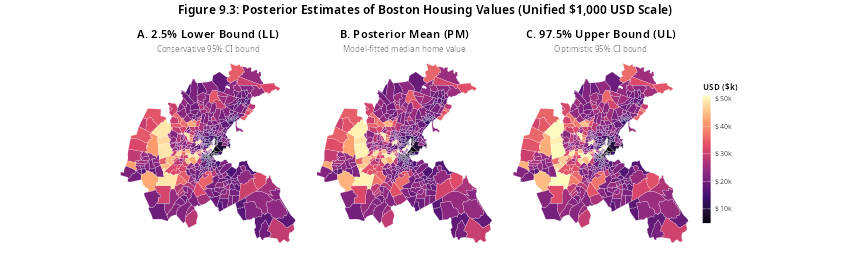

In [13]:
options(ark.plot.width = 11.8, ark.plot.height = 3.6, repr.plot.width = 11.8, repr.plot.height = 3.6)
(p_ll | p_pm | p_ul) +
  plot_annotation(
    title = "Figure 9.3: Posterior Estimates of Boston Housing Values (Unified $1,000 USD Scale)",
    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 12))
  )


### Notes on Figure 9.3
* **Unified Color Space**: Because all three maps share an identical color scale ($[\$5\text{k}, \$55\text{k}]$), visual comparisons across panels reflect true posterior uncertainty without scale distortion.
* **Posterior Point Estimate (Panel B)**:
  * Reflects both covariate adjustments (`CRIM`, `RM`) and borrowed spatial strength from neighbors.
  * Captures the high-value suburban perimeter ($\ge \$40\text{k}$) vs. the lower-income central urban core ($\le \$18\text{k}$) with smoothed spatial boundaries.
* **Credible Interval Bandwidth (Panels A & C)**:
  * For the majority of tracts, the $95\%$ credible interval is compact ($[PM - \$2\text{k}, PM + \$2\text{k}]$), indicating high model precision.
  * Tracts with larger discrepancies between Lower and Upper limits correspond to peripheral zones with fewer neighbors, where posterior uncertainty naturally expands due to reduced spatial borrowing.
